In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import os

train_df = pd.read_csv('train.csv')
val_df = pd.read_csv('val.csv')

print(f"Train images: {len(train_df)}")
print(f"Val images:   {len(val_df)}")
print(f"Classes ({len(train_df['label'].unique())}): {sorted(train_df['label'].unique())}")

Matplotlib is building the font cache; this may take a moment.


Train images: 67428
Val images:   16858
Classes (7): ['discuss', 'focus', 'hand-raising', 'read', 'standing', 'turn-head', 'write']


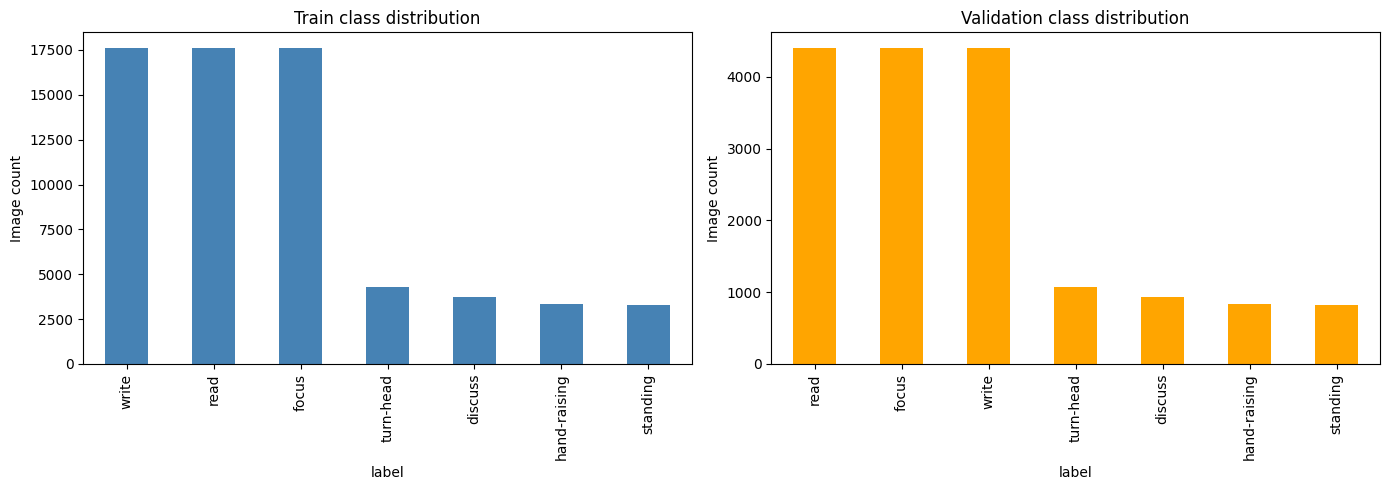


Train counts:
label
write           17600
read            17600
focus           17600
turn-head        4271
discuss          3730
hand-raising     3346
standing         3281
Name: count, dtype: int64

Val counts:
label
read            4400
focus           4400
write           4400
turn-head       1068
discuss          933
hand-raising     837
standing         820
Name: count, dtype: int64


In [2]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

train_df['label'].value_counts().plot(kind='bar', ax=axes[0], color='steelblue')
axes[0].set_title('Train class distribution')
axes[0].set_ylabel('Image count')

val_df['label'].value_counts().plot(kind='bar', ax=axes[1], color='orange')
axes[1].set_title('Validation class distribution')
axes[1].set_ylabel('Image count')

plt.tight_layout()
plt.show()

print("\nTrain counts:")
print(train_df['label'].value_counts())
print("\nVal counts:")
print(val_df['label'].value_counts())

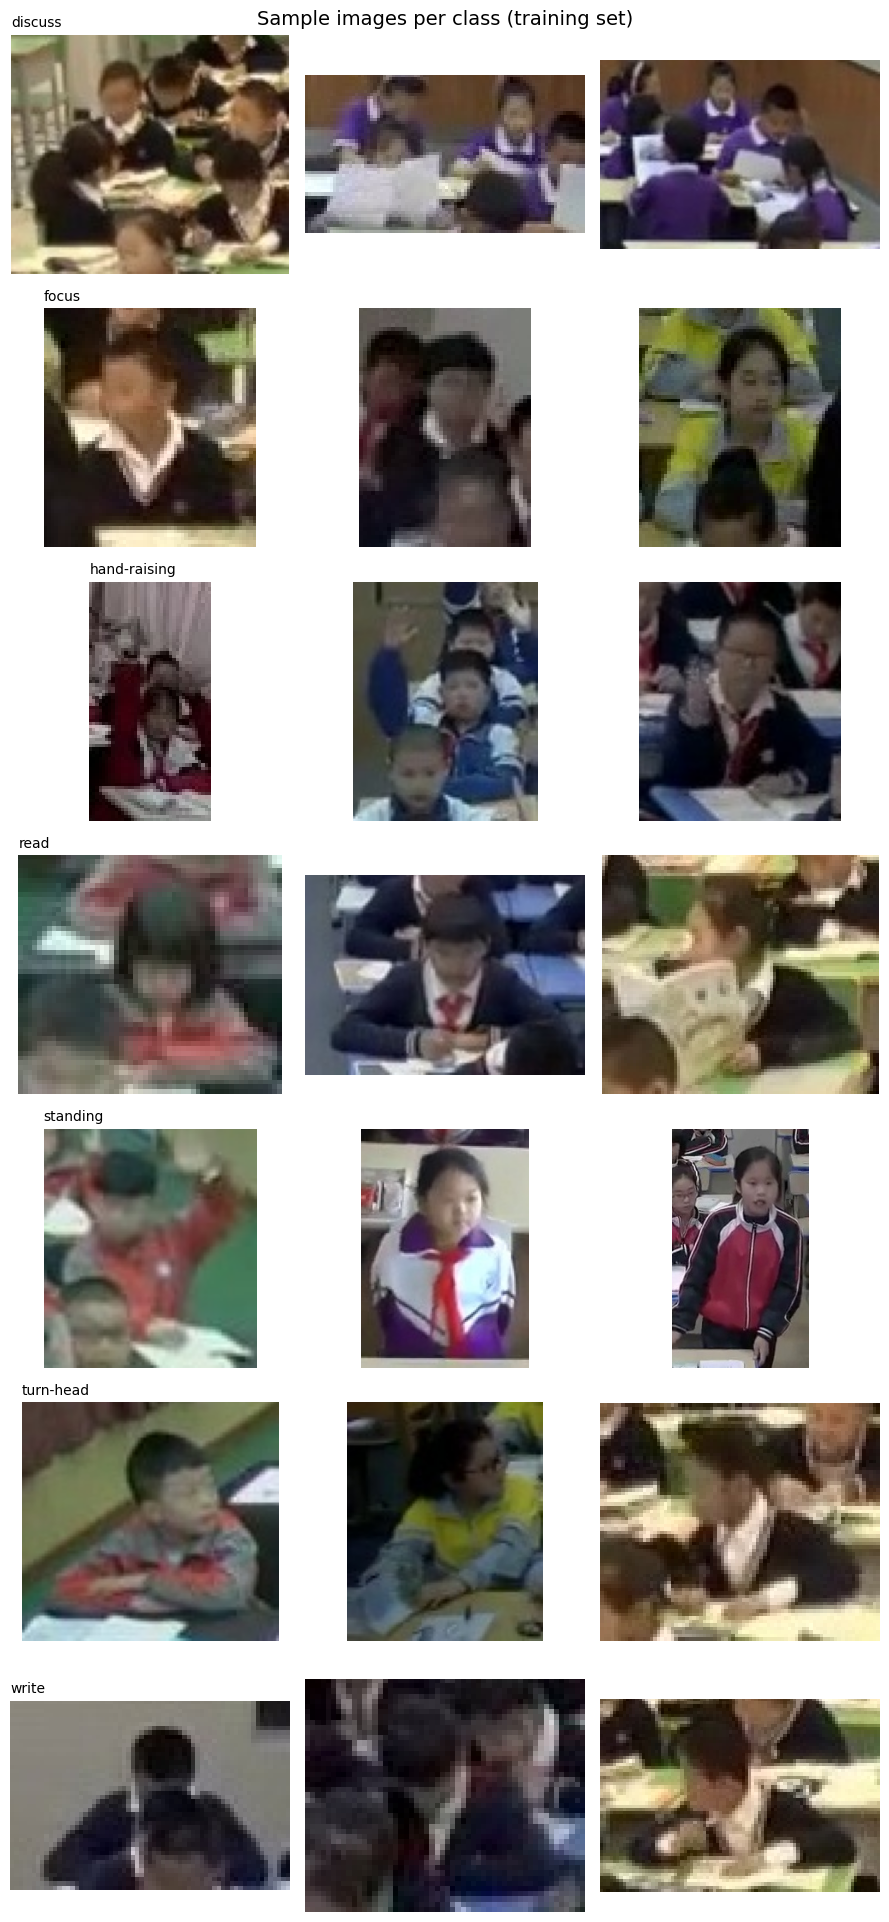

In [3]:
classes = sorted(train_df['label'].unique())
n_samples = 3

fig, axes = plt.subplots(len(classes), n_samples, figsize=(n_samples * 3, len(classes) * 2.8))

for i, cls in enumerate(classes):
    samples = train_df[train_df['label'] == cls].sample(n=n_samples, random_state=42)
    for j, (_, row) in enumerate(samples.iterrows()):
        img = Image.open(row['image_path']).convert('RGB')
        axes[i, j].imshow(img)
        axes[i, j].axis('off')
        if j == 0:
            axes[i, j].set_title(cls, fontsize=10, loc='left')

plt.suptitle('Sample images per class (training set)', fontsize=14)
plt.tight_layout()
plt.show()

In [4]:
train_paths = set(train_df['image_path'])
val_paths = set(val_df['image_path'])
overlap = train_paths.intersection(val_paths)

print(f"Train unique paths: {len(train_paths)}")
print(f"Val unique paths:   {len(val_paths)}")
print(f"Overlapping paths:  {len(overlap)}")

if len(overlap) == 0:
    print("\n✅ CONFIRMED: No duplicate file paths found between train and validation splits.")
    print("   The split is clean — no data leakage detected.")
else:
    print(f"\n❌ WARNING: {len(overlap)} duplicate paths found. Leakage detected!")

Train unique paths: 67428
Val unique paths:   16858
Overlapping paths:  0

✅ CONFIRMED: No duplicate file paths found between train and validation splits.
   The split is clean — no data leakage detected.
